# 06 Age interactions: are some factors more strongly linked to heart disease in young adults?

For five candidate "young-adult stories" we ask: **is the factor's link with self-reported heart disease stronger in adults aged 18–39 than in older adults?** For each factor we fit logistic models with a factor × age-band interaction on the **training** rows, test the interaction with a likelihood-ratio test, and then refit on the **validation** rows to see whether the pattern repeats. The test split is not read. ChestScan and PneumoVaxEver are never used.

All results are associations in survey data, not causes.

## 0. Setup

Import the libraries.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from scipy import stats

Make `src/` importable and load the shared helpers. `load_split` refuses the test split.

In [2]:
sys.path.insert(0, str(Path.cwd().parent / "src"))
from modelling import TARGET, POST_DIAGNOSIS_FEATURES, load_split, check_no_forbidden_columns

ROOT = Path.cwd().parent
OUT_DIR = ROOT / "results/stories"
FIG_DIR = ROOT / "results/figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("statsmodels", statsmodels.__version__, "| pandas", pd.__version__)

statsmodels 0.15.0 | pandas 3.0.6


## 1. Load the data and define the age bands and factors

Load the training and validation splits.

In [3]:
splits = {"training": load_split("training"), "validation": load_split("validation")}
{name: frame.shape for name, frame in splits.items()}

{'training': (308080, 41), 'validation': (66016, 41)}

Group AgeCategory into three bands: 18–39, 40–64 and 65+. Rows with a missing age are dropped, and the count is reported.

In [4]:
BANDS = ["18-39", "40-64", "65+"]

def age_band(category):
    if pd.isna(category):
        return np.nan
    low = int(category.split()[1])          # "Age 18 to 24" -> 18, "Age 80 or older" -> 80
    return "18-39" if low < 40 else ("40-64" if low < 65 else "65+")

for name, frame in splits.items():
    frame["age_band"] = frame["AgeCategory"].map(age_band)
    n_missing = int(frame["age_band"].isna().sum())
    splits[name] = frame[frame["age_band"].notna()].copy()
    print(f"{name}: dropped {n_missing:,} rows with missing age; {len(splits[name]):,} remain")
pd.crosstab(splits["training"]["AgeCategory"], splits["training"]["age_band"])

training: dropped 6,136 rows with missing age; 301,944 remain
validation: dropped 1,255 rows with missing age; 64,761 remain


age_band,18-39,40-64,65+
AgeCategory,,,
Age 18 to 24,18668,0,0
Age 25 to 29,15330,0,0
Age 30 to 34,17929,0,0
Age 35 to 39,19885,0,0
Age 40 to 44,0,20775,0
Age 45 to 49,0,19849,0
Age 50 to 54,0,23210,0
Age 55 to 59,0,25483,0
Age 60 to 64,0,30879,0


Define the five binary factors. A factor is missing when its source question is missing, so each model uses complete cases.

In [5]:
DAILY_SMOKER = "Current smoker - now smokes every day"
assert DAILY_SMOKER in set(splits["training"]["SmokerStatus"].dropna())

def binary(condition, source):
    return condition.astype(float).where(source.notna())

for frame in splits.values():
    frame["Stroke"] = binary(frame["HadStroke"] == "Yes", frame["HadStroke"])
    frame["AllTeethRemoved"] = binary(frame["RemovedTeeth"] == "All", frame["RemovedTeeth"])
    frame["KidneyDisease"] = binary(frame["HadKidneyDisease"] == "Yes", frame["HadKidneyDisease"])
    frame["ShortSleep"] = binary(frame["SleepHours"] <= 4, frame["SleepHours"])
    frame["DailySmoker"] = binary(frame["SmokerStatus"] == DAILY_SMOKER, frame["SmokerStatus"])

FACTORS = {"Stroke": "HadStroke == Yes", "AllTeethRemoved": "RemovedTeeth == All",
           "KidneyDisease": "HadKidneyDisease == Yes", "ShortSleep": "SleepHours <= 4",
           "DailySmoker": "SmokerStatus == now smokes every day"}
splits["training"][list(FACTORS)].agg(["mean", "count"]).round(4)

,Stroke,AllTeethRemoved,KidneyDisease,ShortSleep,DailySmoker
mean,0.0429,0.0584,0.0457,0.041,0.0877
count,301265.0000,294787.0000,300918.0000,298659.000,279019.0000


**Outcome (section 1):** after dropping rows with a missing age (6,136 training, 1,255 validation), 301,944 training and 64,761 validation rows remain. The bands are 18–39 (71,812 training rows), 40–64 (120,196) and 65+ (109,936). The factor prevalences in training are: stroke 4.3%, all teeth removed 5.8%, kidney disease 4.6%, sleeping 4 hours or less 4.1%, smoking every day 8.8%.

## 2. Model specification

- **Model A (minimal):** `heart_disease ~ factor * age_band + Sex`
- **Model B (adjusted):** Model A + GeneralHealth + HadDiabetes + SmokerStatus (SmokerStatus is left out for DailySmoker, because the factor is one of its levels).

Reference levels: age band 18–39, Female, Excellent, No (diabetes), Never smoked. The factor's odds ratio **within** a band combines the main effect and that band's interaction coefficient; its CI uses the coefficient covariance matrix. The interaction is tested with a likelihood-ratio test (the model with vs without the two `factor:age_band` terms, on the same rows).

Build a design matrix by hand (dummy columns with explicit references), so the coefficients are easy to read.

In [6]:
COVARIATE_REFS = {"Sex": "Female", "GeneralHealth": "Excellent", "HadDiabetes": "No", "SmokerStatus": "Never smoked"}

def covariates_for(factor, model):
    covs = ["Sex"]
    if model == "B":
        covs += ["GeneralHealth", "HadDiabetes"] + ([] if factor == "DailySmoker" else ["SmokerStatus"])
    return covs

def design(frame, factor, covariates, interaction=True):
    X = pd.DataFrame({"const": 1.0, "factor": frame[factor]}, index=frame.index)
    for band in BANDS[1:]:
        X[f"age_{band}"] = (frame["age_band"] == band).astype(float)
    if interaction:
        for band in BANDS[1:]:
            X[f"factor:age_{band}"] = X["factor"] * X[f"age_{band}"]
    for cov in covariates:
        for level in sorted(set(frame[cov]) - {COVARIATE_REFS[cov]}):
            X[f"{cov}=={level}"] = (frame[cov] == level).astype(float)
    return X

Fit one factor × model × split: complete cases, both models (with and without the interaction), the within-band odds ratios and the raw rates per band.

In [7]:
def fit_one(frame, factor, model, split):
    covs = covariates_for(factor, model)
    data = frame.dropna(subset=[factor, "age_band", *covs])
    check_no_forbidden_columns(data[[factor, *covs]], [*POST_DIAGNOSIS_FEATURES, TARGET])
    y = data[TARGET].to_numpy()
    full = sm.Logit(y, design(data, factor, covs)).fit(method="newton", maxiter=100, disp=False)
    reduced = sm.Logit(y, design(data, factor, covs, interaction=False)).fit(method="newton", maxiter=100, disp=False)
    assert full.mle_retvals["converged"] and reduced.mle_retvals["converged"], (factor, model, split)
    lr_stat = 2 * (full.llf - reduced.llf)
    lr_p = stats.chi2.sf(lr_stat, df=len(BANDS) - 1)
    cov = full.cov_params()
    rows = []
    for band in BANDS:
        terms = ["factor"] + ([] if band == BANDS[0] else [f"factor:age_{band}"])
        w = pd.Series(0.0, index=full.params.index); w[terms] = 1.0
        est = float(w @ full.params); se = float(np.sqrt(w @ cov @ w))
        in_band = data[data["age_band"] == band]
        with_f, without_f = in_band[in_band[factor] == 1], in_band[in_band[factor] == 0]
        rate_with, rate_without = with_f[TARGET].mean(), without_f[TARGET].mean()
        rows.append({"factor": factor, "model": model, "split": split, "age_band": band,
                     "n": len(in_band), "cases": int(in_band[TARGET].sum()),
                     "n_with_factor": len(with_f), "cases_with_factor": int(with_f[TARGET].sum()),
                     "rate_with": rate_with, "rate_without": rate_without,
                     "risk_ratio": rate_with / rate_without, "pct_points": 100 * (rate_with - rate_without),
                     "odds_ratio": np.exp(est), "ci_low": np.exp(est - 1.96 * se), "ci_high": np.exp(est + 1.96 * se),
                     "interaction_lr_p": lr_p, "n_model": len(data)})
    return rows

## 3. Fit every factor × model × split

Run all 5 factors × 2 models × 2 splits (20 fits, each with and without the interaction).

In [8]:
all_rows = []
for factor in FACTORS:
    for model in ["A", "B"]:
        for split, frame in splits.items():
            all_rows += fit_one(frame, factor, model, split)
results = pd.DataFrame(all_rows)
results.groupby(["factor", "model", "split"])["n_model"].first().unstack("split")

split                  training  validation
factor          model                      
AllTeethRemoved A        294787       63225
                B        271718       58190
DailySmoker     A        279019       59730
                B        277972       59511
KidneyDisease   A        300918       64543
                B        277089       59312
ShortSleep      A        298659       64018
                B        275171       58886
Stroke          A        301265       64592
                B        277362       59362

**Outcome (section 3):** all 40 fits converged (5 factors × 2 models × 2 splits, each with and without the interaction). Complete cases per model range from 271,718 to 301,265 training rows. Model B loses about 7–8% of rows (mostly through missing SmokerStatus), except for DailySmoker, whose Model A already excludes those rows.

## 4. Check the raw rates against the expected values

Compare the training raw rates (Model A rows) for 18–39 and 65+ with the values from the exploratory analysis. The notebook stops if any differs by more than 0.2 percentage points.

In [9]:
EXPECTED = {  # factor: (18-39 with, 18-39 without, 65+ with, 65+ without), in %
    "Stroke": (23.7, 1.0, 39.8, 15.4), "AllTeethRemoved": (8.4, 1.1, 27.4, 16.0),
    "KidneyDisease": (9.1, 1.1, 34.1, 15.7), "ShortSleep": (4.6, 1.0, 26.7, 16.9),
    "DailySmoker": (3.5, 1.0, 22.0, 17.0)}
raw = results[(results["split"] == "training") & (results["model"] == "A")].set_index(["factor", "age_band"])
check = []
for factor, exp in EXPECTED.items():
    got = [100 * raw.loc[(factor, "18-39"), "rate_with"], 100 * raw.loc[(factor, "18-39"), "rate_without"],
           100 * raw.loc[(factor, "65+"), "rate_with"], 100 * raw.loc[(factor, "65+"), "rate_without"]]
    check.append({"factor": factor, **{f"{k} got": round(g, 2) for k, g in zip(["young with", "young without", "65+ with", "65+ without"], got)},
                  "max abs diff": round(max(abs(g - e) for g, e in zip(got, exp)), 2)})
check = pd.DataFrame(check)
assert (check["max abs diff"] <= 0.2).all(), check
check

,factor,young with got,young without got,65+ with got,65+ without got,max abs diff
0,Stroke,23.74,1.00,39.75,15.36,0.05
1,AllTeethRemoved,8.43,1.13,27.40,15.95,0.05
2,KidneyDisease,9.06,1.08,34.12,15.71,0.04
3,ShortSleep,4.58,1.01,26.68,16.91,0.02
4,DailySmoker,3.48,0.98,21.97,17.03,0.03


**Outcome (section 4):** the training raw rates match the expected values to within 0.05 percentage points for every factor (for example, stroke 23.74% vs 1.00% in 18–39 and 39.75% vs 15.36% in 65+), so the bands and factor definitions are the ones used in the exploratory analysis.

## 5. Within-band odds ratios and the interaction test

Odds ratio of each factor in each age band, with 95% CI, and the interaction p-value (training and validation, both models).

In [10]:
fmt = results.assign(OR=results.apply(lambda r: f"{r.odds_ratio:.2f} ({r.ci_low:.2f}-{r.ci_high:.2f})", axis=1))
(fmt.pivot_table(index=["factor", "model", "split"], columns="age_band", values="OR", aggfunc="first")
    .join(results.groupby(["factor", "model", "split"])["interaction_lr_p"].first().map(lambda p: f"{p:.2g}")))

18-39             40-64  \
factor          model split                                               
AllTeethRemoved A     training      8.68 (6.17-12.21)  4.08 (3.80-4.39)   
                      validation    9.55 (4.53-20.13)  4.07 (3.47-4.78)   
                B     training       3.94 (2.68-5.79)  2.11 (1.95-2.29)   
                      validation    5.54 (2.45-12.53)  2.04 (1.71-2.44)   
DailySmoker     A     training       3.62 (3.05-4.29)  2.09 (1.96-2.22)   
                      validation     4.76 (3.33-6.80)  2.16 (1.90-2.46)   
                B     training       2.64 (2.22-3.14)  1.51 (1.42-1.61)   
                      validation     3.50 (2.44-5.03)  1.58 (1.38-1.80)   
KidneyDisease   A     training      9.89 (7.70-12.70)  5.28 (4.89-5.70)   
                      validation    7.90 (4.19-14.90)  4.97 (4.19-5.91)   
                B     training       4.86 (3.70-6.39)  2.66 (2.44-2.89)   
                      validation     4.43 (2.24-8.73)  2.55 (2.12-3.08)   
ShortSleep      A     training       4.63 (3.85-5.58)  3.05 (2.83-3.29)   
                      validation     4.50 (2.97-6.81)  2.92 (2.48-3.43)   
                B     training       3.04 (2.49-3.70)  1.67 (1.54-1.82)   
                      validation     2.84 (1.82-4.43)  1.63 (1.36-1.95)   
Stroke          A     training    33.17 (26.67-41.25)  8.07 (7.51-8.66)   
                      validation  34.13 (21.41-54.43)  8.36 (7.14-9.79)   
                B     training    17.20 (13.52-21.89)  4.26 (3.94-4.61)   
                      validation  20.14 (12.06-33.61)  4.61 (3.88-5.49)   

                                               65+ interaction_lr_p  
factor          model split                                          
AllTeethRemoved A     training    2.00 (1.92-2.10)          1.2e-63  
                      validation  2.01 (1.82-2.22)          6.9e-14  
                B     training    1.30 (1.24-1.37)          3.3e-26  
                      validation  1.30 (1.17-1.45)            3e-06  
DailySmoker     A     training    1.34 (1.26-1.43)          2.3e-36  
                      validation  1.23 (1.06-1.41)            4e-14  
                B     training    1.06 (0.99-1.13)          2.1e-25  
                      validation  0.97 (0.83-1.12)          2.4e-11  
KidneyDisease   A     training    2.83 (2.70-2.97)          5.2e-51  
                      validation  2.78 (2.51-3.08)          8.6e-09  
                B     training    1.76 (1.67-1.86)          2.1e-22  
                      validation  1.77 (1.58-1.98)          0.00046  
ShortSleep      A     training    1.81 (1.68-1.96)          8.1e-29  
                      validation  2.10 (1.78-2.48)          0.00074  
                B     training    1.11 (1.02-1.22)          5.6e-21  
                      validation  1.28 (1.06-1.54)           0.0051  
Stroke          A     training    3.63 (3.46-3.81)         4.7e-120  
                      validation  3.57 (3.22-3.96)          2.5e-28  
                B     training    2.54 (2.41-2.67)          6.2e-60  
                      validation  2.52 (2.25-2.83)          1.3e-16

Raw rates side by side: heart-disease rate with and without the factor, the risk ratio and the percentage-point difference (training, Model A rows, which have the most complete cases).

In [11]:
(results[(results["split"] == "training") & (results["model"] == "A")]
 [["factor", "age_band", "n", "cases", "n_with_factor", "rate_with", "rate_without", "risk_ratio", "pct_points"]]
 .assign(rate_with=lambda d: (100 * d["rate_with"]).round(1), rate_without=lambda d: (100 * d["rate_without"]).round(1))
 .round(2))

,factor,age_band,n,cases,n_with_factor,rate_with,rate_without,risk_ratio,pct_points
0,Stroke,18-39,71720,831,514,23.7,1.0,23.84,22.74
1,Stroke,40-64,119978,7561,4161,31.0,5.4,5.73,25.59
2,Stroke,65+,109567,18842,8241,39.8,15.4,2.59,24.39
12,AllTeethRemoved,18-39,71065,834,451,8.4,1.1,7.47,7.30
13,AllTeethRemoved,40-64,118141,7422,5354,19.3,5.7,3.41,13.65
14,AllTeethRemoved,65+,105581,18151,11415,27.4,16.0,1.72,11.45
24,KidneyDisease,18-39,71683,836,817,9.1,1.1,8.42,7.98
25,KidneyDisease,40-64,119855,7563,4187,23.4,5.7,4.12,17.74
26,KidneyDisease,65+,109380,18799,8754,34.1,15.7,2.17,18.41
36,ShortSleep,18-39,71233,831,3055,4.6,1.0,4.52,3.57


**Outcome (section 5):** for every factor and both models the odds ratio falls steadily from 18–39 to 40–64 to 65+. Model B, training: stroke 17.2 → 4.26 → 2.54; all teeth removed 3.94 → 2.11 → 1.30; kidney disease 4.86 → 2.66 → 1.76; short sleep 3.04 → 1.67 → 1.11; daily smoking 2.64 → 1.51 → 1.06 (its 65+ CI, 0.99–1.13, includes 1). Every training interaction test gives p < 1e-20. The raw rates tell a different story on the absolute scale: the percentage-point gap is never largest in 18–39 (stroke +22.7 vs +24.4 in 65+; kidney disease +8.0 vs +18.4).

## 6. Confirmation rule

A story counts as **confirmed** for a model if (1) the training interaction p < 0.05, (2) in training the 18–39 odds ratio is larger than the 65+ odds ratio (the direction the story claims), and (3) validation shows the same ordering. Otherwise it is "not confirmed". Condition (2) is added so that a significant interaction in the opposite direction is not counted as support.

In [12]:
def band_or(factor, model, split, band):
    r = results[(results["factor"] == factor) & (results["model"] == model) & (results["split"] == split) & (results["age_band"] == band)]
    return float(r["odds_ratio"].iloc[0]), float(r["interaction_lr_p"].iloc[0])

summary = []
for factor in FACTORS:
    for model in ["A", "B"]:
        y_tr, p_tr = band_or(factor, model, "training", "18-39")
        o_tr, _ = band_or(factor, model, "training", "65+")
        y_va, p_va = band_or(factor, model, "validation", "18-39")
        o_va, _ = band_or(factor, model, "validation", "65+")
        confirmed = (p_tr < 0.05) and (y_tr > o_tr) and (y_va > o_va)
        summary.append({"factor": factor, "model": model, "train_OR_18_39": y_tr, "train_OR_65plus": o_tr,
                        "train_interaction_p": p_tr, "valid_OR_18_39": y_va, "valid_OR_65plus": o_va,
                        "valid_interaction_p": p_va, "confirmed": "confirmed" if confirmed else "not confirmed"})
summary = pd.DataFrame(summary)
results["confirmed"] = results.merge(summary[["factor", "model", "confirmed"]], on=["factor", "model"], how="left")["confirmed"].to_numpy()
summary.round(4)

,factor,model,train_OR_18_39,train_OR_65plus,train_interaction_p,valid_OR_18_39,valid_OR_65plus,valid_interaction_p,confirmed
0,Stroke,A,33.1716,3.6317,0.0,34.1330,3.5687,0.0000,confirmed
1,Stroke,B,17.1995,2.5363,0.0,20.1369,2.5209,0.0000,confirmed
2,AllTeethRemoved,A,8.6806,2.0044,0.0,9.5549,2.0089,0.0000,confirmed
3,AllTeethRemoved,B,3.9398,1.3041,0.0,5.5384,1.2994,0.0000,confirmed
4,KidneyDisease,A,9.8861,2.8309,0.0,7.8991,2.7777,0.0000,confirmed
5,KidneyDisease,B,4.8593,1.7601,0.0,4.4270,1.7676,0.0005,confirmed
6,ShortSleep,A,4.6334,1.8134,0.0,4.5025,2.1001,0.0007,confirmed
7,ShortSleep,B,3.0372,1.1128,0.0,2.8368,1.2812,0.0051,confirmed
8,DailySmoker,A,3.6197,1.3401,0.0,4.7614,1.2258,0.0000,confirmed
9,DailySmoker,B,2.6378,1.0591,0.0,3.5049,0.9653,0.0000,confirmed


Save one row per factor × model × split × age band.

In [13]:
COLUMNS = ["factor", "model", "split", "age_band", "n", "cases", "rate_with", "rate_without", "risk_ratio",
           "pct_points", "odds_ratio", "ci_low", "ci_high", "interaction_lr_p", "confirmed"]
results[COLUMNS].to_csv(OUT_DIR / "age_interactions.csv", index=False)
print("rows saved:", len(results))

rows saved: 60


**Outcome (section 6):** all 10 factor × model combinations are **confirmed**: training p < 0.05, the 18–39 OR exceeds the 65+ OR in training, and validation repeats that ordering. Validation interaction p-values are larger because the split is smaller (Model B: from 0.005 for short sleep to 1e-16 for stroke), but all are below 0.05. 60 rows are saved in `results/stories/age_interactions.csv`.

## 7. Figure

Odds ratio of each factor by age band (training, Model B) with 95% CIs, on a log scale. The dashed line at 1 means no association.

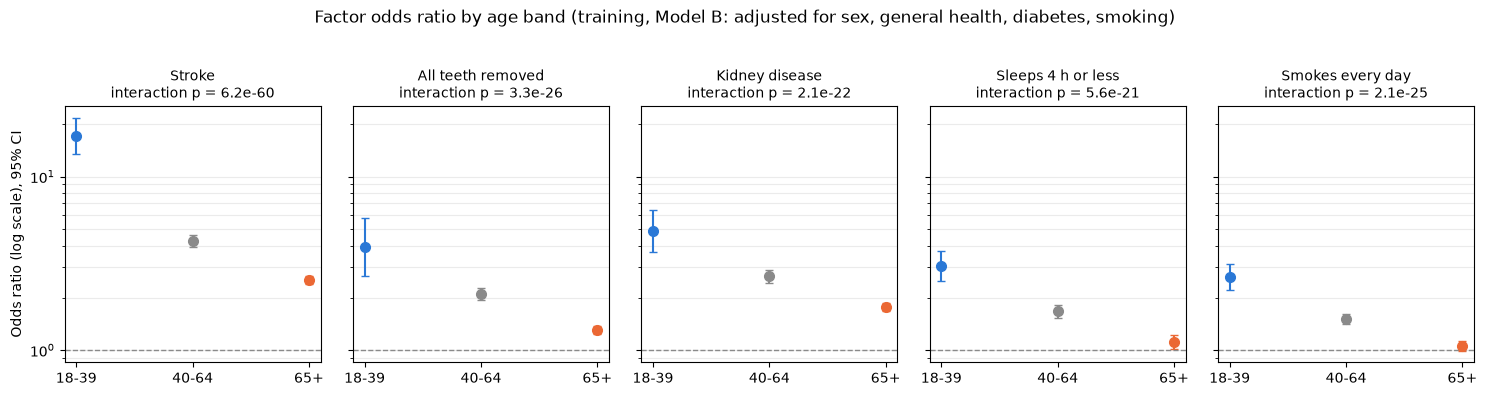

In [14]:
LABELS = {"Stroke": "Stroke", "AllTeethRemoved": "All teeth removed", "KidneyDisease": "Kidney disease",
          "ShortSleep": "Sleeps 4 h or less", "DailySmoker": "Smokes every day"}
band_colors = {"18-39": "#2a78d6", "40-64": "#8a8a8a", "65+": "#eb6834"}
plot = results[(results["split"] == "training") & (results["model"] == "B")]
fig, axes = plt.subplots(1, len(FACTORS), figsize=(15, 3.8), sharey=True)
for ax, factor in zip(axes, FACTORS):
    sub = plot[plot["factor"] == factor].set_index("age_band").loc[BANDS]
    for i, band in enumerate(BANDS):
        r = sub.loc[band]
        ax.errorbar(i, r["odds_ratio"], yerr=[[r["odds_ratio"] - r["ci_low"]], [r["ci_high"] - r["odds_ratio"]]],
                    fmt="o", color=band_colors[band], ms=7, capsize=3, lw=1.5)
    p = sub["interaction_lr_p"].iloc[0]
    ax.set_title(f"{LABELS[factor]}\ninteraction p = {p:.2g}", fontsize=10)
    ax.set_xticks(range(len(BANDS))); ax.set_xticklabels(BANDS)
    ax.axhline(1, ls="--", color="#8a8a8a", lw=1)
    ax.set_yscale("log"); ax.grid(axis="y", alpha=0.25, which="both")
axes[0].set_ylabel("Odds ratio (log scale), 95% CI")
fig.suptitle("Factor odds ratio by age band (training, Model B: adjusted for sex, general health, diabetes, smoking)", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "s01_age_interactions.png", dpi=300, bbox_inches="tight")
plt.show()

**Outcome (section 7):** the figure shows the same falling pattern in all five panels. The 18–39 intervals are much wider than the 65+ ones because few young adults have both the factor and heart disease. Saved as `results/figures/s01_age_interactions.png`.

## 8. Summary

**Outcome:** all five stories are **confirmed** under both models. In training the factor's odds ratio is largest in 18–39 and smallest in 65+, every interaction test gives p < 1e-20, and validation repeats the ordering (validation interaction p from 0.005 to below 1e-10). Age is missing for 6,136 training and 1,255 validation rows, and these rows were dropped. The raw training rates match the expected values to within 0.05 percentage points.

| Factor | OR 18–39 (Model B, training) | OR 65+ (Model B, training) | Interaction p (training) | Validation 18–39 vs 65+ | Confirmed |
|---|---|---|---|---|---|
| Stroke | 17.2 (13.5–21.9) | 2.54 (2.41–2.67) | 6e-60 | 20.1 vs 2.52 | yes |
| All teeth removed | 3.94 (2.68–5.79) | 1.30 (1.24–1.37) | 3e-26 | 5.54 vs 1.30 | yes |
| Kidney disease | 4.86 (3.70–6.39) | 1.76 (1.67–1.86) | 2e-22 | 4.43 vs 1.77 | yes |
| Sleeps 4 h or less | 3.04 (2.49–3.70) | 1.11 (1.02–1.22) | 6e-21 | 2.84 vs 1.28 | yes |
| Smokes every day | 2.64 (2.22–3.14) | 1.06 (0.99–1.13) | 2e-25 | 3.50 vs 0.97 | yes |

Model A (adjusted only for sex) shows the same pattern with larger odds ratios (for example, stroke 33.2 in 18–39 vs 3.63 in 65+). Adjusting for general health, diabetes and smoking roughly halves the young-adult odds ratios, but the gap between age bands remains.

**Caution: "stronger" holds on the relative scale only.** Heart disease is rare in young adults (about 1% without the factor, against 15–17% in 65+), so the same absolute difference gives a much larger odds or risk ratio in the young. In percentage points the young band is **never** the largest (training, raw rates):

- Stroke: +22.7 points in 18–39 (23.7% vs 1.0%), +24.4 in 65+ (39.8% vs 15.4%)
- All teeth removed: +7.3 vs +11.5
- Kidney disease: +8.0 vs +18.4
- Sleeps 4 h or less: +3.6 vs +9.8
- Smokes every day: +2.5 vs +4.9

So the honest story is: *relative to their peers*, young adults with these factors stand out much more, but the extra heart-disease burden in absolute terms is similar or larger in older adults. Report both scales. The young-band estimates also rest on few cases (for example, 514 young adults with a stroke, 122 of them with heart disease), so their confidence intervals are wide. These are associations in self-reported cross-sectional survey data, not causes. For example, a stroke and heart disease share causes and are often diagnosed together. Saved in `results/stories/age_interactions.csv`; figure `results/figures/s01_age_interactions.png`.